# Soil Core Image Preprocessing

This notebook downloads `grano1/core_sample_image_data` from Hugging Face and completes the image preprocessing pipeline only. It does not define or train a CNN. Run the cells from top to bottom.

In [1]:
from pathlib import Path
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
PROJECT_ROOT = next((p for p in candidates if (p / 'ml_backend').is_dir()), cwd)
MODEL_DIR = PROJECT_ROOT / 'ml_backend' / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

DATASET_ID = 'grano1/core_sample_image_data'
IMAGE_COLUMN = 'image'
LABEL_COLUMN = 'HB'
IMAGE_SIZE = 128
BATCH_SIZE = 32
NUM_WORKERS = 0
print(f'Project root: {PROJECT_ROOT}')
print(f'PyTorch: {torch.__version__}')

c:\Users\ARJUN MITRA\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: D:\Work space\infosys springboard project\Infosys-Sp7.0-TeamB-Batch-4-Soil-Analytics
PyTorch: 2.11.0+cu128


## Load and inspect the Hugging Face image dataset

In [2]:
dataset = load_dataset(DATASET_ID)
print(dataset)
print('Splits:', list(dataset.keys()))
for split, table in dataset.items():
    print(f'{split}: {len(table)} rows; columns={table.column_names}')
    print(table.features)

DatasetDict({
    train: Dataset({
        features: ['Bildname', 'HB', 'NB', 'image'],
        num_rows: 2883
    })
    val: Dataset({
        features: ['Bildname', 'HB', 'NB', 'image'],
        num_rows: 360
    })
    test: Dataset({
        features: ['Bildname', 'HB', 'NB', 'image'],
        num_rows: 361
    })
})
Splits: ['train', 'val', 'test']
train: 2883 rows; columns=['Bildname', 'HB', 'NB', 'image']
{'Bildname': Value('string'), 'HB': Value('string'), 'NB': List(Value('string')), 'image': Image(mode=None, decode=True)}
val: 360 rows; columns=['Bildname', 'HB', 'NB', 'image']
{'Bildname': Value('string'), 'HB': Value('string'), 'NB': List(Value('string')), 'image': Image(mode=None, decode=True)}
test: 361 rows; columns=['Bildname', 'HB', 'NB', 'image']
{'Bildname': Value('string'), 'HB': Value('string'), 'NB': List(Value('string')), 'image': Image(mode=None, decode=True)}


In [3]:
def image_info(value):
    image = value.convert('RGB') if isinstance(value, Image.Image) else Image.open(value).convert('RGB')
    return image.size, image.mode

for split, table in dataset.items():
    missing = {column: sum(value is None for value in table[column]) for column in table.column_names}
    labels = sorted(set(table[LABEL_COLUMN]))
    sizes = []
    modes = set()
    for value in table[IMAGE_COLUMN][:min(len(table), 200)]:
        size, mode = image_info(value)
        sizes.append(size)
        modes.add(mode)
    print(f'\n{split}')
    print('Missing values:', missing)
    print('Labels:', labels)
    print('Sample image sizes:', sorted(set(sizes)))
    print('Sample image modes:', sorted(modes))


train
Missing values: {'Bildname': 0, 'HB': 0, 'NB': 0, 'image': 0}
Labels: ['G', 'S', 'T', 'U', 'fG', 'fS', 'fS+U', 'fS+mS', 'gS', 'mG', 'mS']
Sample image sizes: [(330, 330)]
Sample image modes: ['RGB']

val
Missing values: {'Bildname': 0, 'HB': 0, 'NB': 0, 'image': 0}
Labels: ['G', 'S', 'T', 'U', 'fG', 'fS', 'fS+U', 'fS+mS', 'gS', 'mG', 'mS']
Sample image sizes: [(330, 330)]
Sample image modes: ['RGB']

test
Missing values: {'Bildname': 0, 'HB': 0, 'NB': 0, 'image': 0}
Labels: ['G', 'S', 'T', 'U', 'fG', 'fS', 'fS+U', 'fS+mS', 'gS', 'mG', 'mS']
Sample image sizes: [(330, 330)]
Sample image modes: ['RGB']


## Exploratory graphs before preprocessing

These plots summarize split sizes, HB class balance, RGB distributions, and correlations between image statistics.

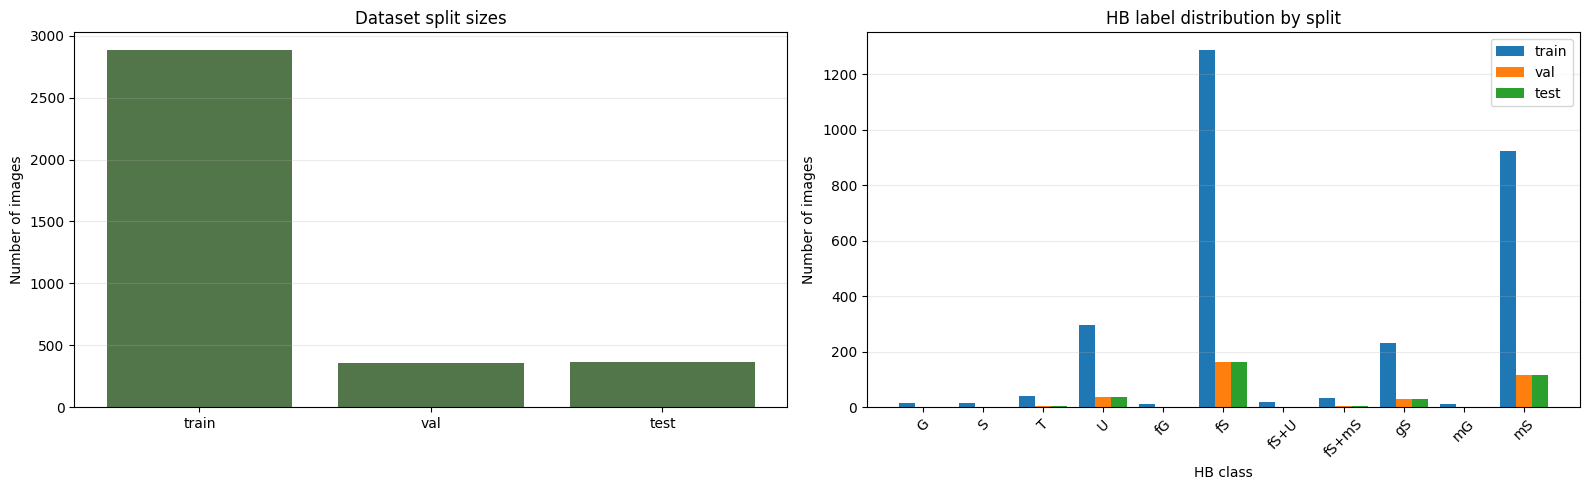

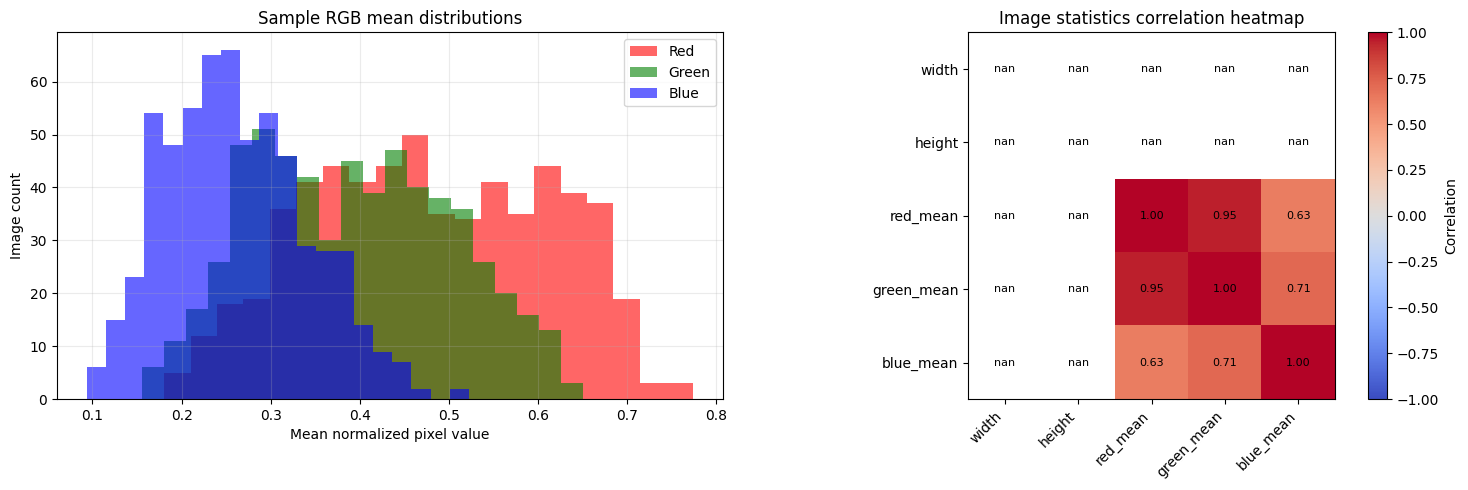

       width  height  red_mean  green_mean  blue_mean
split                                                
test   330.0   330.0    0.4851      0.3977     0.2607
train  330.0   330.0    0.4755      0.3935     0.2650
val    330.0   330.0    0.4711      0.3873     0.2611


In [10]:
from collections import Counter

split_names = list(dataset.keys())
plot_labels = sorted(set(dataset['train'][LABEL_COLUMN]))
label_counts = {split: Counter(dataset[split][LABEL_COLUMN]) for split in split_names}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].bar(split_names, [len(dataset[split]) for split in split_names], color='#52764a')
axes[0].set_title('Dataset split sizes')
axes[0].set_ylabel('Number of images')
axes[0].grid(axis='y', alpha=0.25)

x = np.arange(len(plot_labels))
width = 0.8 / len(split_names)
for index, split in enumerate(split_names):
    counts = [label_counts[split].get(label, 0) for label in plot_labels]
    axes[1].bar(x + index * width, counts, width=width, label=split)
axes[1].set_title('HB label distribution by split')
axes[1].set_xlabel('HB class')
axes[1].set_ylabel('Number of images')
axes[1].set_xticks(x + width * (len(split_names) - 1) / 2, plot_labels, rotation=45)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

sample_rows = []
for split in split_names:
    sample = dataset[split].select(range(min(len(dataset[split]), 200)))
    for row in sample:
        image = row[IMAGE_COLUMN].convert('RGB')
        pixels = np.asarray(image, dtype=np.float32) / 255.0
        sample_rows.append({
            'split': split,
            'width': image.width,
            'height': image.height,
            'red_mean': pixels[:, :, 0].mean(),
            'green_mean': pixels[:, :, 1].mean(),
            'blue_mean': pixels[:, :, 2].mean(),
        })

image_stats = pd.DataFrame(sample_rows)
numeric_stats = image_stats[['width', 'height', 'red_mean', 'green_mean', 'blue_mean']]
correlation = numeric_stats.corr()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for channel, color in [('red_mean', 'red'), ('green_mean', 'green'), ('blue_mean', 'blue')]:
    axes[0].hist(image_stats[channel], bins=20, alpha=0.6, label=channel.replace('_mean', '').title(), color=color)
axes[0].set_title('Sample RGB mean distributions')
axes[0].set_xlabel('Mean normalized pixel value')
axes[0].set_ylabel('Image count')
axes[0].legend()
axes[0].grid(alpha=0.25)

heatmap = axes[1].imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
axes[1].set_title('Image statistics correlation heatmap')
axes[1].set_xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha='right')
axes[1].set_yticks(range(len(correlation.index)), correlation.index)
for row_index in range(len(correlation.index)):
    for column_index in range(len(correlation.columns)):
        value = correlation.iloc[row_index, column_index]
        axes[1].text(column_index, row_index, f'{value:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(heatmap, ax=axes[1], label='Correlation')
plt.tight_layout()
plt.show()
print(image_stats.groupby('split')[numeric_stats.columns].mean().round(4))

In [11]:
label_names = sorted(set(dataset['train'][LABEL_COLUMN]))
label_to_id = {name: index for index, name in enumerate(label_names)}
id_to_label = {index: name for name, index in label_to_id.items()}
NORMALIZE = ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(8),
    transforms.ToTensor(),
    transforms.Normalize(*NORMALIZE),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(*NORMALIZE),
])
print('Label mapping:', label_to_id)
print('Image tensor shape:', (3, IMAGE_SIZE, IMAGE_SIZE))

Label mapping: {'G': 0, 'S': 1, 'T': 2, 'U': 3, 'fG': 4, 'fS': 5, 'fS+U': 6, 'fS+mS': 7, 'gS': 8, 'mG': 9, 'mS': 10}
Image tensor shape: (3, 128, 128)


In [12]:
class SoilCoreDataset(Dataset):
    def __init__(self, table, image_transform):
        self.table = table
        self.image_transform = image_transform

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table[index]
        image = row[IMAGE_COLUMN]
        if not isinstance(image, Image.Image):
            image = Image.open(image)
        image = image.convert('RGB')
        tensor = self.image_transform(image)
        label = label_to_id[row[LABEL_COLUMN]]
        return tensor, torch.tensor(label, dtype=torch.long)

validation_split = 'validation' if 'validation' in dataset else 'val'
train_data = SoilCoreDataset(dataset['train'], train_transform)
validation_data = SoilCoreDataset(dataset[validation_split], eval_transform)
test_data = SoilCoreDataset(dataset['test'], eval_transform)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
validation_loader = DataLoader(validation_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
print(f'Preprocessed rows: train={len(train_data)}, {validation_split}={len(validation_data)}, test={len(test_data)}')

Preprocessed rows: train=2883, val=360, test=361


In [13]:
images, labels = next(iter(train_loader))
print('Batch image shape:', tuple(images.shape))
print('Batch label shape:', tuple(labels.shape))
print('Pixel range after normalization:', float(images.min()), float(images.max()))
assert images.shape == (min(BATCH_SIZE, len(train_data)), 3, IMAGE_SIZE, IMAGE_SIZE)
assert labels.dtype == torch.long

Batch image shape: (32, 3, 128, 128)
Batch label shape: (32,)
Pixel range after normalization: -2.1179039478302 1.8550388813018799


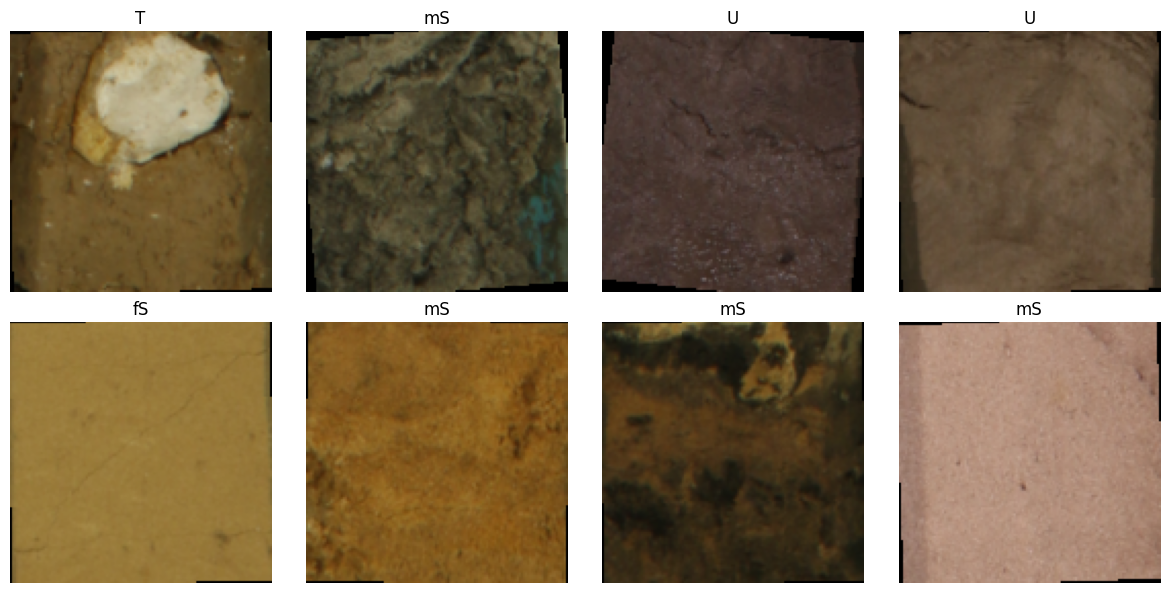

In [8]:
def show_tensor(image_tensor, title):
    mean = torch.tensor(NORMALIZE[0]).view(3, 1, 1)
    std = torch.tensor(NORMALIZE[1]).view(3, 1, 1)
    image = (image_tensor.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    plt.imshow(image)
    plt.title(title)
    plt.axis('off')

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for axis, image, label in zip(axes.flat, images[:8], labels[:8]):
    plt.sca(axis)
    show_tensor(image, id_to_label[int(label)])
plt.tight_layout()
plt.show()

## Save preprocessing metadata

The metadata file can be loaded by a later training or inference notebook. No model weights are created here.

In [9]:
metadata = {
    'dataset': DATASET_ID,
    'image_column': IMAGE_COLUMN,
    'label_column': LABEL_COLUMN,
    'image_size': IMAGE_SIZE,
    'channels': 3,
    'normalize_mean': list(NORMALIZE[0]),
    'normalize_std': list(NORMALIZE[1]),
    'label_names': label_names,
    'label_to_id': label_to_id,
    'split_sizes': {split: len(table) for split, table in dataset.items()},
}
metadata_path = MODEL_DIR / 'soil_core_preprocessing.json'
metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print(f'Saved preprocessing metadata to: {metadata_path}')

Saved preprocessing metadata to: D:\Work space\infosys springboard project\Infosys-Sp7.0-TeamB-Batch-4-Soil-Analytics\ml_backend\models\soil_core_preprocessing.json
